In [ ]:
import os
from pathlib import Path

REPO_DIR = "/content"
SDK_DIR = "/content/ptcg_sdk"

repo = Path(REPO_DIR).expanduser().resolve() if REPO_DIR else next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "team_a/configs/evaluation.json").is_file()), None)
if repo is None or not (repo / "team_a/configs/evaluation.json").is_file():
    raise ValueError("Set REPO_DIR to your repository checkout in Colab.")
if not SDK_DIR:
    raise ValueError("Set SDK_DIR to the official SDK directory containing cg/ and deck.csv.")
sdk = Path(SDK_DIR).expanduser().resolve()
for relative in ("cg/game.py", "cg/sim.py", "deck.csv"):
    if not (sdk / relative).is_file():
        raise FileNotFoundError(sdk / relative)


In [6]:
import json
import platform
import sys
import tempfile
import time

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

if sys.platform != "linux":
    raise RuntimeError("Run native evaluation in Colab/Linux, not on the local Mac.")
sys.path.insert(0, str(repo))
from team_a.src.common_runtime import load_config, resolve_agent, stage_agent, verify_decks
from team_a.src.evaluation import run_pair
from team_a.src.models.jiayi.agents import stage_policy

config = load_config()
seeds = list(range(60000, 60040))
print("Python:", sys.version.split()[0], "Platform:", platform.platform())
print("40 individual battles per policy; heuristic opponent; seeds 60000–60039")
print("Step limit:", config["max_steps"], "Worker timeout:", config["process_timeout_seconds"])


Python: 3.13.18 Platform: Linux-6.6.159+-x86_64-with-glibc2.39
40 individual battles per policy; heuristic opponent; seeds 60000–60039
Step limit: 10000 Worker timeout: 1200


In [ ]:
rows, summaries = [], []
result_path = repo / "team_a/src/models/jiayi/evaluation_results.csv"

with tempfile.TemporaryDirectory(prefix="jiayi_evaluation_") as temporary:
    root = Path(temporary)
    opponent = root / "heuristic"
    opponent_info = stage_agent(resolve_agent(config, alias="heuristic"), opponent, sdk / "deck.csv")
    for model_id in ("A-J1", "A-J2"):
        candidate = root / model_id
        candidate_info = stage_policy(model_id, candidate, sdk / "deck.csv")
        verify_decks(candidate_info, opponent_info, config)
        output = root / (model_id + "_results")
        started = time.perf_counter()
        passed, summary = run_pair(
            candidate, opponent, sdk, output, config, seeds, "jiayi_heuristic", model_id,
            {"candidate": candidate_info, "opponent": opponent_info})
        elapsed = time.perf_counter() - started
        report_path = output / "report.json"
        report = json.loads(report_path.read_text()) if report_path.exists() else {}
        process = json.loads((output / "process.json").read_text())
        for row in report.get("battles", []):
            rows.append({"policy": model_id, "opponent": "heuristic", "unit": "individual_battle",
                         **{key: value for key, value in row.items()
                            if key not in ("policy_usage", "selection_types")}})
        if rows:
            pd.DataFrame(rows).to_csv(result_path, index=False)
        summaries.append({
            "policy": model_id, "requested": len(seeds), "recorded": len(report.get("battles", [])),
            "completed": summary.get("valid_battles", 0),
            "wins": summary.get("win", 0), "losses": summary.get("loss", 0),
            "draws": summary.get("draw", 0), "win_rate": summary.get("win_rate"),
            "failed_battles": summary.get("error", 0),
            "unknown_results": summary.get("unknown_result", 0),
            "invalid_responses": summary.get("invalid_responses", 0),
            "engine_rejections": summary.get("engine_rejections", 0),
            "battle_seconds": sum(row.get("seconds") or 0 for row in report.get("battles", [])),
            "wall_seconds": elapsed, "passed": passed,
            "worker_returncode": process["returncode"], "timed_out": process["timed_out"]})
        print(model_id, "passed:" , passed, "worker:", process)
        if not passed:
            print("Worker error:", report.get("error"))
            for filename in ("stdout.txt", "stderr.txt"):
                print(filename, (output / filename).read_text()[-6000:])
        display(pd.DataFrame([summaries[-1]]))

comparison = pd.DataFrame(summaries).set_index("policy")
display(comparison)
if rows:
    print("Saved actual battle records:", result_path.relative_to(repo))
else:
    print("No battle records produced; no result CSV written. Any existing CSV is from a prior run.")


A-J1 passed: True worker: {'returncode': 0, 'timed_out': False, 'error': None, 'command': ['/usr/bin/python3', '/content/team_a/scripts/evaluate.py', '--worker', '/tmp/jiayi_evaluation_4pgohgu5/A-J1_results/job.json']}


,policy,requested,recorded,completed,wins,losses,draws,win_rate,failed_battles,unknown_results,invalid_responses,engine_rejections,battle_seconds,wall_seconds,passed,worker_returncode,timed_out
0,A-J1,40,40,40,19,21,0,0.475,0,0,0,0,0.866954,1.083545,True,0,False


A-J2 passed: True worker: {'returncode': 0, 'timed_out': False, 'error': None, 'command': ['/usr/bin/python3', '/content/team_a/scripts/evaluate.py', '--worker', '/tmp/jiayi_evaluation_4pgohgu5/A-J2_results/job.json']}


,policy,requested,recorded,completed,wins,losses,draws,win_rate,failed_battles,unknown_results,invalid_responses,engine_rejections,battle_seconds,wall_seconds,passed,worker_returncode,timed_out
0,A-J2,40,40,40,20,20,0,0.5,0,0,0,0,2.800971,2.983867,True,0,False


,requested,recorded,completed,wins,losses,draws,win_rate,failed_battles,unknown_results,invalid_responses,engine_rejections,battle_seconds,wall_seconds,passed,worker_returncode,timed_out
policy,,,,,,,,,,,,,,,,
A-J1,40,40,40,19,21,0,0.475,0,0,0,0,0.866954,1.083545,True,0,False
A-J2,40,40,40,20,20,0,0.500,0,0,0,0,2.800971,2.983867,True,0,False


Saved actual battle records: team_a/src/models/jiayi/evaluation_results.csv


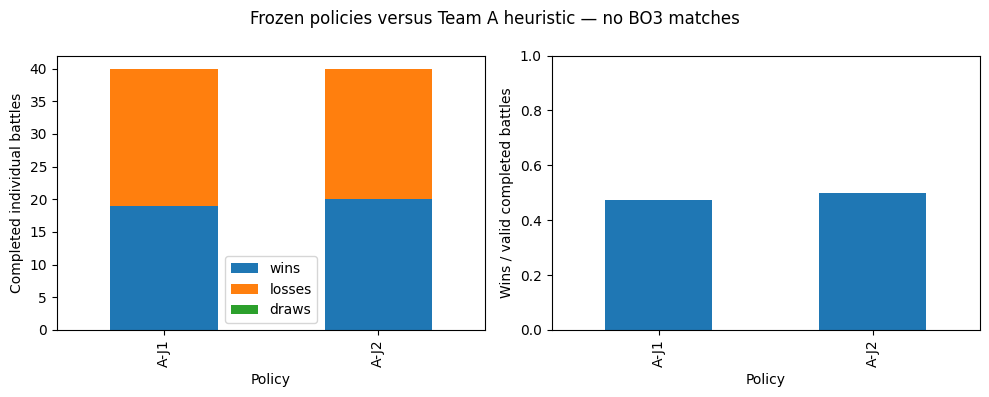

Failures are excluded from win-rate denominators and must be reported separately.
This small comparison does not establish statistically reliable superiority.


In [8]:
if comparison["completed"].gt(0).any():
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    comparison[["wins", "losses", "draws"]].plot.bar(stacked=True, ax=axes[0])
    axes[0].set(ylabel="Completed individual battles", xlabel="Policy")
    comparison.loc[comparison["completed"] > 0, "win_rate"].plot.bar(ax=axes[1], ylim=(0, 1))
    axes[1].set(ylabel="Wins / valid completed battles", xlabel="Policy")
    fig.suptitle("Frozen policies versus Team A heuristic — no BO3 matches")
    plt.tight_layout()
    plt.show()
else:
    print("No completed battles: no gameplay rates or plot available.")
print("Failures are excluded from win-rate denominators and must be reported separately.")
print("This small comparison does not establish statistically reliable superiority.")
